In [1]:
import pandas as pd

df = pd.read_csv("../datasets/unified_febrile_disease_dataset.csv")

print("Original dataset shape:", df.shape)
print(df["Disease"].value_counts())

Original dataset shape: (2203, 16)
Disease
Chikungunya    1001
Dengue          618
Typhoid         500
Malaria          84
Name: count, dtype: int64


In [2]:
df_clean = df.drop_duplicates().copy()

print("Original records:", len(df))
print("After removing duplicates:", len(df_clean))

print("\nDisease distribution:")
print(df_clean["Disease"].value_counts())

Original records: 2203
After removing duplicates: 1071

Disease distribution:
Disease
Chikungunya    916
Dengue         106
Malaria         33
Typhoid         16
Name: count, dtype: int64


In [3]:
feature_columns = [
    col for col in df_clean.columns
    if col != "Disease"
]

X = df_clean[feature_columns]
y = df_clean["Disease"]

print("Features:")
print(feature_columns)

print("\nTarget classes:")
print(y.unique())

Features:
['Fever', 'Headache', 'Nausea', 'Muscle_Pain_Myalgia', 'Vomiting', 'Diarrhea', 'Joint_Pain', 'Arthritis', 'Joint_Swelling', 'Rash', 'Chills', 'Sweating', 'Fatigue', 'Eye_Orbital_Pain', 'Conjunctivitis']

Target classes:
<ArrowStringArray>
['Typhoid', 'Chikungunya', 'Malaria', 'Dengue']
Length: 4, dtype: str


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 856
Testing records: 215


In [5]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [6]:
y_pred = model.predict(X_test)

print(y_pred[:20])

['Chikungunya' 'Chikungunya' 'Chikungunya' 'Chikungunya' 'Chikungunya'
 'Chikungunya' 'Chikungunya' 'Chikungunya' 'Chikungunya' 'Chikungunya'
 'Chikungunya' 'Chikungunya' 'Chikungunya' 'Chikungunya' 'Chikungunya'
 'Chikungunya' 'Chikungunya' 'Chikungunya' 'Chikungunya' 'Chikungunya']


In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)
recall = recall_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)
f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)

print("\nDetailed classification report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Accuracy : 0.9674418604651163
Precision: 0.7125
Recall   : 0.7023809523809523
F1-score : 0.7073170731707317

Detailed classification report:
              precision    recall  f1-score   support

 Chikungunya       1.00      1.00      1.00       184
      Dengue       0.85      0.81      0.83        21
     Malaria       1.00      1.00      1.00         7
     Typhoid       0.00      0.00      0.00         3

    accuracy                           0.97       215
   macro avg       0.71      0.70      0.71       215
weighted avg       0.97      0.97      0.97       215



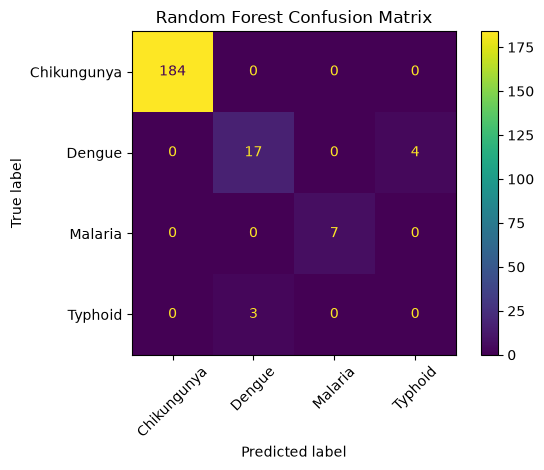

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=45
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

In [9]:
probabilities = model.predict_proba(X_test)

print("Disease classes:")
print(model.classes_)

print("\nProbabilities for first test case:")
for disease, probability in zip(
    model.classes_,
    probabilities[0]
):
    print(f"{disease}: {probability:.3f}")

Disease classes:
['Chikungunya' 'Dengue' 'Malaria' 'Typhoid']

Probabilities for first test case:
Chikungunya: 1.000
Dengue: 0.000
Malaria: 0.000
Typhoid: 0.000


In [11]:
def predict_disease(input_features):
    input_df = pd.DataFrame(
        [input_features],
        columns=feature_columns
    )

    probabilities = model.predict_proba(input_df)[0]

    best_index = probabilities.argmax()
    predicted_disease = model.classes_[best_index]
    max_probability = probabilities[best_index]

    return predicted_disease, max_probability, probabilities

In [12]:
demo_patient = [
    1,  # Fever
    1,  # Headache
    1,  # Nausea
    1,  # Muscle_Pain_Myalgia
    1,  # Vomiting
    0,  # Diarrhea
    1,  # Joint_Pain
    1,  # Arthritis
    1,  # Joint_Swelling
    1,  # Rash
    0,  # Chills
    0,  # Sweating
    1,  # Fatigue
    1,  # Eye_Orbital_Pain
    1   # Conjunctivitis
]

disease, probability, probabilities = predict_disease(
    demo_patient
)

print("Predicted disease:", disease)
print("Model probability:", round(probability, 3))

Predicted disease: Chikungunya
Model probability: 1.0


In [13]:
threshold = 0.80

if probability >= threshold:
    final_result = disease
else:
    final_result = "Unknown / Uncertain Case"

print("Final result:", final_result)
print("Maximum probability:", round(probability, 3))

Final result: Chikungunya
Maximum probability: 1.0


In [15]:
import joblib

joblib.dump(
    model,
    "../models/febrile_random_forest_demo.pkl"
)

joblib.dump(
    feature_columns,
    "../models/feature_columns.pkl"
)

print("Demo model saved.")

Demo model saved.
